In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [12]:
tips = sns.load_dataset("tips")
tips.head()
tips.dtypes


,0
total_bill,float64
tip,float64
sex,category
smoker,category
day,category
time,category
size,int64


In [11]:
tips["day"].unique()

['Sun', 'Sat', 'Thur', 'Fri']
Categories (4, object): ['Thur', 'Fri', 'Sat', 'Sun']

In [13]:
tips = sns.load_dataset("tips")

encoded = pd.get_dummies(tips, columns=["sex", "smoker", "day", "time"], dtype=int)
encoded.head()

,total_bill,tip,size,sex_Male,sex_Female,smoker_Yes,smoker_No,day_Thur,day_Fri,day_Sat,day_Sun,time_Lunch,time_Dinner
0,16.99,1.01,2,0,1,0,1,0,0,0,1,0,1
1,10.34,1.66,3,1,0,0,1,0,0,0,1,0,1
2,21.01,3.50,3,1,0,0,1,0,0,0,1,0,1
3,23.68,3.31,2,1,0,0,1,0,0,0,1,0,1
4,24.59,3.61,4,0,1,0,1,0,0,0,1,0,1


In [16]:
pd.get_dummies(t.sex)

,Male,Female
0,False,True
1,True,False
2,True,False
3,True,False
4,False,True
...,...,...
239,True,False
240,False,True
241,True,False
242,True,False


In [21]:
encoded2 = pd.get_dummies(tips, columns=["sex", "smoker", "day", "time"],
                          drop_first=True, dtype=int)
encoded2.head()

,total_bill,tip,size,sex_Female,smoker_No,day_Fri,day_Sat,day_Sun,time_Dinner
0,16.99,1.01,2,1,1,0,0,1,1
1,10.34,1.66,3,0,1,0,0,1,1
2,21.01,3.50,3,0,1,0,0,1,1
3,23.68,3.31,2,0,1,0,0,1,1
4,24.59,3.61,4,1,1,0,0,1,1


In [24]:
diamonds = sns.load_dataset("diamonds")
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [25]:
diamonds = sns.load_dataset("diamonds")
diamonds["cut"].unique()

['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Categories (5, object): ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']

In [27]:
cut_order={"fair":0,"Good":1,"Very Good":2,"Premium":3,"Ideal":4}


In [33]:
diamonds["cut_orderno"]=diamonds["cut"].astype(str).map(cut_order)
diamonds[["cut","cut_orderno"]].head(10)

,cut,cut_orderno
0,Ideal,4.0
1,Premium,3.0
2,Good,1.0
3,Premium,3.0
4,Good,1.0
5,Very Good,2.0
6,Very Good,2.0
7,Very Good,2.0
8,Fair,NaN
9,Very Good,2.0


In [36]:
diamonds.head(10)
diamonds["cut_orderno"].isna().sum()

np.int64(1610)

In [37]:
diamonds.groupby("cut")["price"].mean().round(0)

/tmp/ipykernel_575/4012644273.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diamonds.groupby("cut")["price"].mean().round(0)


,price
cut,
Ideal,3458.0
Premium,4584.0
Very Good,3982.0
Good,3929.0
Fair,4359.0


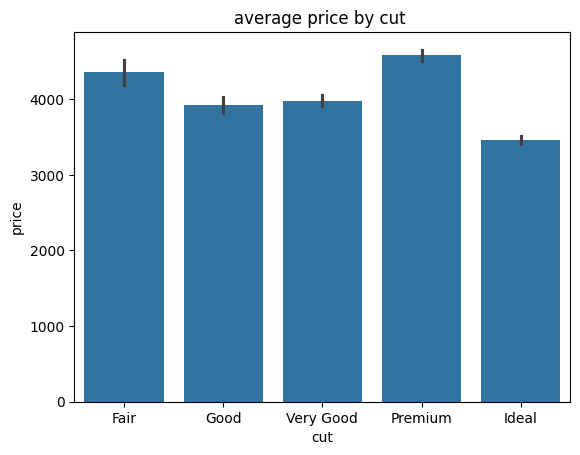

In [39]:
sns.barplot(data=diamonds,x="cut",y="price",order=["Fair", "Good", "Very Good", "Premium", "Ideal"])
plt.title("average price by cut ")
plt.show()


In [40]:
diamonds.groupby("cut")["carat"].mean().round(2)

/tmp/ipykernel_575/2676582867.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  diamonds.groupby("cut")["carat"].mean().round(2)


,carat
cut,
Ideal,0.70
Premium,0.89
Very Good,0.81
Good,0.85
Fair,1.05


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
penguins = sns.load_dataset("penguins").dropna()
penguins.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
12,Adelie,Torgersen,41.1,17.6,182.0,3200.0,Female
13,Adelie,Torgersen,38.6,21.2,191.0,3800.0,Male
14,Adelie,Torgersen,34.6,21.1,198.0,4400.0,Male


In [47]:
cols=["bill_length_mm", "flipper_length_mm", "body_mass_g"]
penguins[cols].describe().round(1)

,bill_length_mm,flipper_length_mm,body_mass_g
count,333.0,333.0,333.0
mean,44.0,201.0,4207.1
std,5.5,14.0,805.2
min,32.1,172.0,2700.0
25%,39.5,190.0,3550.0
50%,44.5,197.0,4050.0
75%,48.6,213.0,4775.0
max,59.6,231.0,6300.0


In [51]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled = scaler.fit_transform(penguins[cols])
scaled_df=pd.DataFrame(scaled,columns=cols)
scaled_df.head(10)

,bill_length_mm,flipper_length_mm,body_mass_g
0,-0.896042,-1.426752,-0.568475
1,-0.822788,-1.069474,-0.506286
2,-0.676280,-0.426373,-1.190361
3,-1.335566,-0.569284,-0.941606
4,-0.859415,-0.783651,-0.692852
5,-0.932669,-1.426752,-0.723946
6,-0.877728,-0.426373,0.582014
7,-0.529772,-1.355296,-1.252549
8,-0.987609,-0.712196,-0.506286
9,-1.720150,-0.212006,0.239977


In [52]:
scaled_df.describe().round(2)

,bill_length_mm,flipper_length_mm,body_mass_g
count,333.00,333.00,333.00
mean,0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.18,-2.07,-1.87
25%,-0.82,-0.78,-0.82
50%,0.09,-0.28,-0.20
75%,0.84,0.86,0.71
max,2.86,2.15,2.60


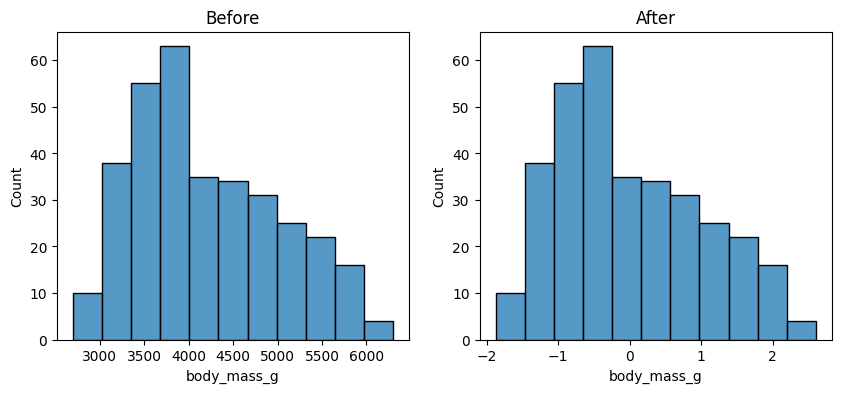

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(penguins["body_mass_g"], ax=axes[0]).set_title("Before")
sns.histplot(scaled_df["body_mass_g"], ax=axes[1]).set_title("After")

plt.show()